In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df1 = pd.read_csv('../data/raw/train_test_combine.csv')

In [3]:
df1.columns

Index(['SMILES', 'PCE'], dtype='object')

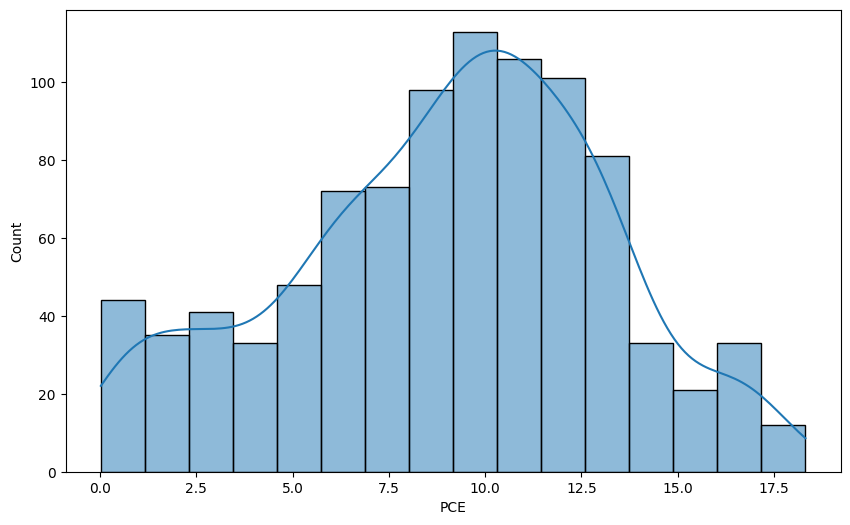

In [4]:
# Set figure size (10 inches by 6 inches)
plt.figure(figsize=(10, 6))

# Create a histogram with KDE
sns.histplot(df1['PCE'], kde=True)

# Save the figure with 900 dpi
plt.savefig('../results/figures/histogram_of_pce.png', dpi=900)

# Show the plot
plt.show()

In [5]:
df2 = pd.read_csv('../data/raw/First_Database.csv')

In [6]:
df2.columns

Index(['Unnamed: 0', 'Donor_Smiles', 'Acceptor_Smiles', 'PCE (%)', 'VOC (V)',
       'JSC (mA/cm−2)', 'FF (%)', 'Dhomo', 'Dlumo', 'Donor_Eg_opt', 'Ahomo',
       'Alumo', 'Acceptor_Eg_opt', 'S_No', 'Ref.', 'S_Ref'],
      dtype='object')

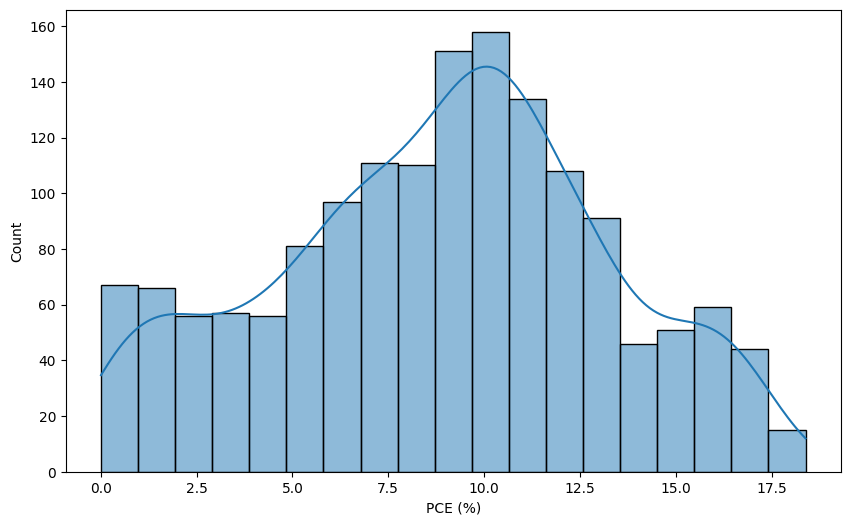

In [7]:
# Set figure size (10 inches by 6 inches)
plt.figure(figsize=(10, 6))

# Create a histogram with KDE
sns.histplot(df2['PCE (%)'], kde=True)

# Save the figure with 900 dpi
plt.savefig('../results/figures/histogram_of_pce_first_database.png', dpi=900)

# Show the plot
plt.show()

In [8]:
# https://www.rdkit.org/
#https://github.com/rdkit/rdkit
from rdkit.Chem import AllChem
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.ML.Descriptors import MoleculeDescriptors

# https://pandas.pydata.org
import pandas as pd

# https://numpy.org/doc/stable/release.html
import numpy as np

#https://github.com/mordred-descriptor/mordred
from mordred import Calculator, descriptors

In [9]:
df1.columns

Index(['SMILES', 'PCE'], dtype='object')

In [10]:
df2.columns

Index(['Unnamed: 0', 'Donor_Smiles', 'Acceptor_Smiles', 'PCE (%)', 'VOC (V)',
       'JSC (mA/cm−2)', 'FF (%)', 'Dhomo', 'Dlumo', 'Donor_Eg_opt', 'Ahomo',
       'Alumo', 'Acceptor_Eg_opt', 'S_No', 'Ref.', 'S_Ref'],
      dtype='object')

In [11]:
# Create a list for duplicate smiles
duplicates_smiles_df1 = df1[df1['SMILES'].duplicated()]['SMILES'].values
len(duplicates_smiles_df1)

32

In [12]:
# Create a list for duplicate smiles
duplicates_smiles_df2 = df2[df2['Acceptor_Smiles'].duplicated()]['Acceptor_Smiles'].values
len(duplicates_smiles_df2)

795

In [13]:
# Create a list for duplicate smiles
df1[df1['SMILES'].isin(duplicates_smiles_df1)].sort_values(by=['SMILES'])

,SMILES,PCE
930,CCCCC(CC)CC1(CC(CC)CCCC)C2=C(C=C3CC4=C(SC(/C=C...,13.150
905,CCCCC(CC)CC1(CC(CC)CCCC)C2=C(C=C3CC4=C(SC(/C=C...,13.180
195,CCCCC(CC)CC1(CC(CC)CCCC)C2=C(SC(/C=C3\C(=O)C4=...,7.320
634,CCCCC(CC)CC1(CC(CC)CCCC)C2=C(SC(/C=C3\C(=O)C4=...,8.450
431,CCCCC(CC)CC1=C2C(=O)C3=C(C4=CC5=C(S4)C4=C(C=C(...,12.400
185,CCCCC(CC)CC1=C2C(=O)C3=C(C4=CC5=C(S4)C4=C(C=C(...,6.580
251,CCCCC(CC)CC1=C2C(=O)C3=C(C4=CC5=C(S4)C4=C(C=C(...,8.390
439,CCCCC(CC)CN1C(=O)C2=CC=C(C#CC3=CC=C(C4=CC=C(C5...,0.510
325,CCCCC(CC)CN1C(=O)C2=CC=C(C#CC3=CC=C(C4=CC=C(C5...,0.700
506,CCCCCCC1(CCCCCC)C2=CC3=C(C=C2C2=C1C=C(/C=C1\C(...,9.430


In [14]:
# Create a list for duplicate smiles
df2[df2['Acceptor_Smiles'].isin(duplicates_smiles_df2)].sort_values(by=['Acceptor_Smiles'])

,Unnamed: 0,Donor_Smiles,Acceptor_Smiles,PCE (%),VOC (V),JSC (mA/cm−2),FF (%),Dhomo,Dlumo,Donor_Eg_opt,Ahomo,Alumo,Acceptor_Eg_opt,S_No,Ref.,S_Ref
1524,1524,CCCCCCCCC(CCCCCC)COc1cnc2c(C)c(F)c(F)c(-c3ccc(...,CC(C)c1cccc(C(C)C)c1N1C(=O)c2cc3cc4c(cc3cc2C1=...,3.82,1.020,9.52,39.80,-5.54,-2.98,2.56,-5.62,-3.90,1.72,1525,549,Same as Saeki et al.
1523,1523,CCCCCCCCC(CCCCCC)COc1cnc2c(C)c(F)c(F)c(-c3ccc(...,CC(C)c1cccc(C(C)C)c1N1C(=O)c2cc3cc4c(cc3cc2C1=...,2.17,1.010,5.85,38.70,-5.54,-2.98,2.56,-5.62,-3.90,1.72,1524,549,Same as Saeki et al.
632,632,CCCCC(CC)CC(=O)c1cc2c(C)sc(-c3cc4c(-c5ccc(CC(C...,CCC(CC)N1C(=O)c2ccc3c4c5c(c6ccc(c2c36)C1=O)=CC...,3.64,0.800,8.10,51.90,-5.11,-3.25,1.86,-5.90,-3.80,2.10,633,176,Same as Saeki et al.
275,275,CCCCC(CC)COC(=O)c1sc2c(-c3cc4c(OCC(CC)CCCC)c5s...,CCC(CC)N1C(=O)c2ccc3c4c5c(c6ccc(c2c36)C1=O)=CC...,3.55,0.840,7.57,55.90,-5.02,-3.39,1.63,-5.90,-3.80,2.10,276,9,Same as Saeki et al.
356,356,CCCCCCc1cc(C)sc1C,CCC(CC)N1C(=O)c2ccc3c4c5c(c6ccc(c2c36)C1=O)=CC...,0.25,0.480,1.49,35.00,-5.00,-3.10,1.90,-5.90,-3.80,2.10,357,42,Same as Saeki et al.
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,195,CCCCCCCCC(CCCCCC)COC(=O)c1cc(C)sc1/C=C/c1sc(-c...,[C-]#[N+]/C(C#N)=C1C(=C/c2sc3c(sc4c5c6nsnc6c6c...,16.20,0.790,26.22,0.78,-5.28,-3.02,1.76,-5.68,-4.12,1.40,196,255,S132
66,66,CCCCC(CC)Cc1cc(-c2c3cc(-c4ccc(-c5sc(-c6ccc(C)s...,[C-]#[N+]/C(C#N)=C1C(=C/c2sc3c(sc4c5c6nsnc6c6c...,17.80,0.839,26.20,81.10,-5.47,-3.56,1.82,-5.64,-4.05,1.40,67,171,S50
435,435,CCCCCCCCCCCCSc1ccc(-c2c3cc(-c4ccc(-c5c(F)c(F)c...,[C-]#[N+]/C(C#N)=c1/s/c(=C\c2ccc(-c3cc4c(s3)-c...,8.03,1.150,10.84,66.20,-5.32,-3.38,1.94,-5.49,-3.73,1.76,436,72,Same as Saeki et al.
957,957,CCCCCCCCC(CCCCCC)Cn1nc2c(-c3ccc(C)s3)c(F)c(F)c...,[C-]#[N+]/C(C#N)=c1/s/c(=C\c2ccc(-c3cc4c(s3)-c...,9.18,1.070,14.62,60.30,-5.13,-3.22,1.91,-5.49,-3.73,1.76,958,322,Same as Saeki et al.


In [15]:
# Keep rows with the highest PCE values for each unique SMILES
df1_new = df1.loc[df1.groupby('SMILES')['PCE'].idxmax()]

# Reset the index
df1_new = df1_new.reset_index(drop=True)

# Check the length of the new DataFrame
len(df1_new)

912

In [16]:
# Keep rows with the highest PCE values for each unique SMILES
df2_new = df2.loc[df2.groupby('Acceptor_Smiles')['PCE (%)'].idxmax()]

# Reset the index
df2_new = df2_new.reset_index(drop=True)

# Check the length of the new DataFrame
len(df2_new)

763

In [17]:
df1_new.columns

Index(['SMILES', 'PCE'], dtype='object')

In [18]:
df2_new.columns

Index(['Unnamed: 0', 'Donor_Smiles', 'Acceptor_Smiles', 'PCE (%)', 'VOC (V)',
       'JSC (mA/cm−2)', 'FF (%)', 'Dhomo', 'Dlumo', 'Donor_Eg_opt', 'Ahomo',
       'Alumo', 'Acceptor_Eg_opt', 'S_No', 'Ref.', 'S_Ref'],
      dtype='object')

In [19]:
df2_new = df2_new.loc[:, ['Acceptor_Smiles', 'PCE (%)']]

In [20]:
df2_new.columns

Index(['Acceptor_Smiles', 'PCE (%)'], dtype='object')

In [21]:
import pandas as pd

# Rename columns in df2 to match df1 for concatenation
df2_new = df2_new.rename(columns={'Acceptor_Smiles': 'SMILES', 'PCE (%)': 'PCE'})

# Concatenate the two DataFrames
combined_df = pd.concat([df1_new[['SMILES', 'PCE']], df2_new[['SMILES', 'PCE']]], ignore_index=True)

# Display the new combined DataFrame
print(combined_df)

                                                 SMILES    PCE
0     C#C/C=C/C(CCCCCC)CN1C(=O)C2=C(C3=CC=C(C4=CC=C(...   4.01
1     C#CC(CCCC)CC1(CC(CC)CCCC)C2=C(SC(C3=C(CCCCCC)C...   0.27
2     C#CC(CCCC)CN1C(=O)C2=C(C3=CC4=C(S3)C3=C(C=C(/C...   9.80
3     CC#CC1=C2N=C3C=C4C(=CC3=NC2=C(C#CC)C2=NSN=C21)...   1.28
4     CC#CC1=C2N=C3C=C4CC5(CC4=CC3=NC2=C(C#CC)C2=NSN...   1.39
...                                                 ...    ...
1670  [C-]#[N+]/C(C#N)=C1C(=C/c2sc3c(sc4c5c6nsnc6c6c...  16.90
1671  [C-]#[N+]/C(C#N)=c1/s/c(=C\c2ccc(-c3cc4c(s3)-c...  10.35
1672  [C-]#[N+]/C(C#N)=c1/s/c(=C\c2ccc(-c3cc4c(s3)-c...   8.13
1673  [C-]#[N+]C1=C(C)/C(=C/c2cc(CCCCCC)c(-c3cc(CCCC...   4.81
1674                   c1cc2ccc3ccc4ccc5ccc1c1c2c3c4c51   0.19

[1675 rows x 2 columns]


In [22]:
# Create a list for duplicate smiles
duplicates_smiles_combined = combined_df[combined_df['SMILES'].duplicated()]['SMILES'].values
len(duplicates_smiles_combined)

0

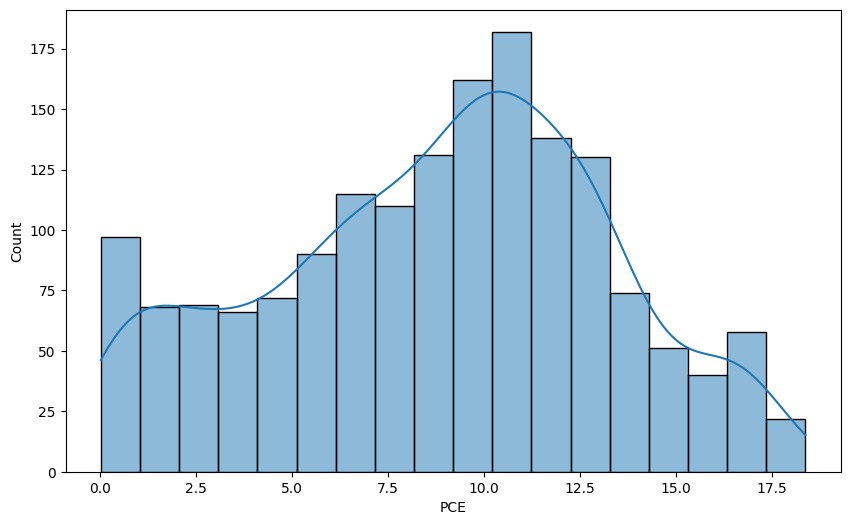

In [23]:
# Set figure size (10 inches by 6 inches)
plt.figure(figsize=(10, 6))

# Create a histogram with KDE
sns.histplot(combined_df['PCE'], kde=True)

# Save the figure with 900 dpi
plt.savefig('../results/figures/histogram_of_pce_combined.png', dpi=900)

# Show the plot
plt.show()

In [24]:
combined_df.columns

Index(['SMILES', 'PCE'], dtype='object')

In [25]:
# Function to return the canonical SMILES from a given SMILES string
def get_canonical_smiles(smiles):
    try:
        mol = Chem.MolFromSmiles(smiles)
        if mol:
            return Chem.MolToSmiles(mol, canonical=True)
        else:
            return None  # Return None if the SMILES is invalid
    except Exception as e:
        return None  # Return None in case of any errors

In [26]:
# Apply the function to the 'SMILES' column and replace original values
combined_df['SMILES'] = combined_df['SMILES'].apply(get_canonical_smiles)

In [27]:
combined_df.columns

Index(['SMILES', 'PCE'], dtype='object')

In [28]:
duplicates_smiles_combined = combined_df[combined_df['SMILES'].duplicated()]['SMILES'].values
len(duplicates_smiles_combined)

194

In [29]:
# Create a list for duplicate smiles
combined_df[combined_df['SMILES'].isin(duplicates_smiles_combined)].sort_values(by=['SMILES'])

,SMILES,PCE
51,CCCCC(CC)CC1(CC(CC)CCCC)c2cc(-c3ccc(/C=C4\C(=O...,0.97
929,CCCCC(CC)CC1(CC(CC)CCCC)c2cc(-c3ccc(/C=C4\C(=O...,2.54
32,CCCCC(CC)CC1(CC(CC)CCCC)c2cc(/C=C3\C(=O)c4cc(C...,8.52
931,CCCCC(CC)CC1(CC(CC)CCCC)c2cc(/C=C3\C(=O)c4cc(C...,11.60
934,CCCCC(CC)CC1(CC(CC)CCCC)c2cc(/C=C3\C(=O)c4cc(F...,11.49
...,...,...
191,CCCCCCc1ccccc1-c1c(/C=C2\C(=O)c3cc(F)c(F)cc3C2...,16.00
1665,COCCOCc1ccc(C2(c3ccc(COCCOC)cc3)c3cc4c(cc3-c3s...,8.40
858,COCCOCc1ccc(C2(c3ccc(COCCOC)cc3)c3cc4c(cc3-c3s...,8.50
759,N#CC(C#N)=C1/C(=C/c2cc3c(s2)-c2cc4c(cc2C3(CCCC...,13.72


In [30]:
# Keep rows with the highest PCE values for each unique SMILES
combined_df = combined_df.loc[combined_df.groupby('SMILES')['PCE'].idxmax()]

# Reset the index
combined_df = combined_df.reset_index(drop=True)

# Check the length of the new DataFrame
len(combined_df)

1481

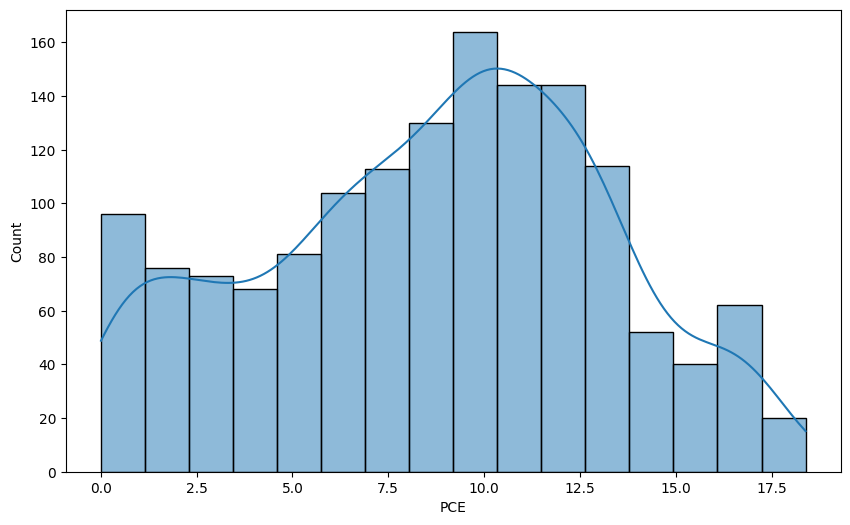

In [31]:
# Set figure size (10 inches by 6 inches)
plt.figure(figsize=(10, 6))

# Create a histogram with KDE
sns.histplot(combined_df['PCE'], kde=True)

# Save the figure with 900 dpi
plt.savefig('../results/figures/histogram_of_pce_combined.png', dpi=900)

# Show the plot
plt.show()

In [32]:
combined_df.to_csv('../data/processed/Combined_df.csv')

Molecular Descriptor Generation

In [ ]:
combined_df.shape

In [ ]:
combined_df.columns

In [ ]:
def RDkit_descriptors(smiles):
    mols = [Chem.MolFromSmiles(i) for i in smiles]
    calc = MoleculeDescriptors.MolecularDescriptorCalculator([x[0] for x in Descriptors._descList])
    desc_names = calc.GetDescriptorNames()

    Mol_descriptors =[]
    for mol in mols:
        # add hydrogens to molecules
        mol=Chem.AddHs(mol)
        # Calculate all 200 descriptors for each molecule
        descriptors = calc.CalcDescriptors(mol)
        Mol_descriptors.append(descriptors)
    return Mol_descriptors,desc_names

# Function call
Mol_descriptors,desc_names = RDkit_descriptors(combined_df['SMILES'])

In [ ]:
df_with_200_descriptors = pd.DataFrame(Mol_descriptors,columns=desc_names)
df_with_200_descriptors

In [ ]:
def All_Mordred_descriptors(data):
    calc = Calculator(descriptors, ignore_3D=False)
    mols = [Chem.MolFromSmiles(smi) for smi in data]

    # pandas df
    df = calc.pandas(mols)
    return df

In [ ]:
mordred_descriptors = All_Mordred_descriptors(combined_df['SMILES'])

In [ ]:
mordred_descriptors.shape

In [ ]:
mordred_descriptors

In [ ]:
df_with_200_descriptors.to_csv('../data/features/rdkit_combined_df.csv')

In [ ]:
mordred_descriptors.to_csv('../data/features/mordred_combined_df.csv')

Molecular Fingerprints

In [ ]:
import warnings
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import Descriptors
from rdkit.Chem import AllChem, PandasTools, MACCSkeys, AtomPairs, rdFingerprintGenerator
from rdkit import DataStructs
from rdkit.Chem.rdmolops import PatternFingerprint
from rdkit.Avalon import pyAvalonTools
from rdkit.Chem.AtomPairs.Pairs import GetAtomPairFingerprintAsBitVect
pd.set_option('display.max_rows', None)

warnings.filterwarnings("ignore")

In [ ]:
PandasTools.AddMoleculeColumnToFrame(combined_df,'SMILES','mol')

In [ ]:
# create an empty list
df_maccs = []

# run a for loop to iterate through each molecule
for mol in combined_df['mol']:
# generate bitvector object
  maccs_bitvector = MACCSkeys.GenMACCSKeys(mol)
# create an empty array
  arr = np.zeros((0,), dtype=np.int8)
# convert the RDKit explicit vectors into numpy arrays
  DataStructs.ConvertToNumpyArray(maccs_bitvector,arr)
# append the array to the empty list
  df_maccs.append(arr)

MACCS = pd.concat([combined_df, pd.DataFrame(df_maccs)], axis=1)

In [ ]:
MACCS.drop('mol', axis=1).to_csv('../data/features/maccs_combined_df.csv', index=None)

In [ ]:
df_pf = []
for mol in combined_df['mol']:
  pf_bitvector = PatternFingerprint(mol)
  arr = np.zeros((0,), dtype=np.int8)
  DataStructs.ConvertToNumpyArray(pf_bitvector,arr)
  df_pf.append(arr)

PF = pd.concat([combined_df, pd.DataFrame(df_pf)], axis=1)

In [ ]:
PF.drop('mol', axis=1).to_csv('../data/features/pf_combined_df.csv', index=None)

In [ ]:
df_mf = []
for mol in combined_df['mol']:
  mf_bitvector = AllChem.GetMorganFingerprintAsBitVect(mol, radius=1, nBits = 2048)
  arr = np.zeros((0,), dtype=np.int8)
  # convert the RDKit explicit vectors into numpy arrays
  DataStructs.ConvertToNumpyArray(mf_bitvector,arr)
  df_mf.append(arr)

MF = pd.concat([combined_df, pd.DataFrame(df_mf)], axis=1)

In [ ]:
MF.drop('mol', axis=1).to_csv('../data/features/morgan_combined_df.csv', index=None)

In [ ]:
df_ecfp = []
for mol in combined_df['mol']:
  ecfp_bitvector = AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits = 2048)
  arr = np.zeros((0,), dtype=np.int8)
  # convert the RDKit explicit vectors into numpy arrays
  DataStructs.ConvertToNumpyArray(ecfp_bitvector,arr)
  df_ecfp.append(arr)

ECFP = pd.concat([combined_df, pd.DataFrame(df_ecfp)], axis=1)

In [ ]:
ECFP.drop('mol', axis=1).to_csv('../data/features/extended_combined_df.csv', index=None)

In [ ]:
df_af = []
for mol in combined_df['mol']:
  af_bitvector = pyAvalonTools.GetAvalonFP(mol, nBits=512)
  arr = np.zeros((0,), dtype=np.int8)
  # convert the RDKit explicit vectors into numpy arrays
  DataStructs.ConvertToNumpyArray(af_bitvector,arr)
  df_af.append(arr)

AF = pd.concat([combined_df, pd.DataFrame(df_af)], axis=1)

In [ ]:
AF.drop('mol', axis=1).to_csv('../data/features/avalon_combined.csv', index=None)

In [ ]:
df_rdk = []
rdkgen = rdFingerprintGenerator.GetRDKitFPGenerator(fpSize=4096)
for mol in combined_df['mol']:
  rdk_bitvector = rdkgen.GetFingerprint(mol)

# convert the RDKit explicit vectors into numpy arrays
  arr = np.array(rdk_bitvector)
  df_rdk.append(arr)

RDK = pd.concat([combined_df, pd.DataFrame(df_rdk)], axis=1)

In [ ]:
RDK.drop('mol', axis=1).to_csv('../data/features/rdk_fingerprint_combined.csv', index=None)

In [ ]:
# create an empty list
df_apf = []

# run a for loop to iterate through each molecule
apgen = rdFingerprintGenerator.GetAtomPairGenerator(fpSize=4096)

for mol in combined_df['mol']:
  apf_bitvector = apgen.GetFingerprint(mol)


# convert the RDKit explicit vectors into numpy arrays
  arr = np.array(apf_bitvector)
  df_apf.append(arr)

APF = pd.concat([combined_df, pd.DataFrame(df_apf)], axis=1)

In [ ]:
APF.drop('mol', axis=1).to_csv('../data/features/apf_combined.csv', index=None)

In [ ]:
df_ttf = []
ttgen = rdFingerprintGenerator.GetTopologicalTorsionGenerator(fpSize=2048)
for mol in combined_df['mol']:
  ttf_bitvector = ttgen.GetFingerprint(mol)

  # convert the RDKit explicit vectors into numpy arrays
  arr = np.array(ttf_bitvector)
  df_ttf.append(arr)

TTF = pd.concat([combined_df, pd.DataFrame(df_ttf)], axis=1)
     

In [ ]:
TTF.drop('mol', axis=1).to_csv('../data/features/ttf_combined.csv', index=None)

Padel Descriptors

In [ ]:
import time
start_time = time.perf_counter()

In [ ]:
!pip install padelpy
import padelpy

In [ ]:
import pandas as pd
import glob
import os
from padelpy import padeldescriptor

In [ ]:
! wget -nc -P ../data/padel_descriptor_xml https://github.com/codetodiscovery/fingerprint-padel/raw/main/descriptors_xml.zip

In [ ]:
! unzip -o ../data/padel_descriptor_xml/descriptors_xml.zip -d ../data/padel_descriptor_xml

In [ ]:
xml_files = glob.glob("../data/padel_descriptor_xml/*.xml")
xml_files.sort()
xml_files

In [ ]:
combined_df.columns

In [ ]:
padel_df = combined_df.loc[:, ['SMILES']]

In [ ]:
padel_df.shape

In [ ]:
padel_df.head()

In [ ]:
padel_df_smi = padel_df.to_csv('../data/processed/combined_df.smi', index=None, header=None)

In [ ]:
for i in range(len(xml_files)):

  fp_name = os.path.basename(xml_files[i])[:-4]
  out_csv = f'../data/features/padel_legacy/{fp_name}.csv'
  padeldescriptor(mol_dir='../data/processed/combined_df.smi', d_file=out_csv,
                  descriptortypes= xml_files[i],retainorder=True,
                  fingerprints=True,d_2d=False,
                  d_3d=False)
  fp = pd.read_csv(out_csv)
  fp = pd.concat([combined_df, fp.drop('Name', axis=1)], axis=1)
  fp.to_csv(out_csv, index=None)
  print (f'{fp_name} done')

end_time = time.perf_counter ()
print(end_time - start_time, "seconds")